# 🎬 Project: YouTube Summarization (Solution)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nawooooojin/openai-api-tutorial-kr/blob/main/Practice_solution/youtube_summarization_project_solution.ipynb)

- **프로젝트 목적**: 유튜브 비디오에서 추출한 오디오를 입력으로 받아 전사 → 요약 → 이미지 생성 → PDF 요약본 생성까지의 전체 흐름을 구현
- 앞에서 배운 **STT · Structured Output · Image Generation**을 한 번에 엮어 보는 종합 프로젝트입니다.

## 1. 환경 준비 및 API 키 설정

In [ ]:
%pip install -q -U openai yt-dlp pydantic reportlab pillow

### API 키 설정 및 Client 생성
- **Colab**: 왼쪽 메뉴 `보안 비밀(열쇠 아이콘)`에 `OPENAI_API_KEY`를 저장하고 **노트북 액세스**를 켜 두면 자동으로 불러옵니다.
- **로컬**: 환경 변수 `OPENAI_API_KEY`를 미리 설정해 두거나, 아래 셀을 실행했을 때 뜨는 입력창에 키를 붙여넣으면 됩니다.
- 아래의 코드에서 오류가 난다면 API 키의 오류일 가능성이 높습니다.

In [1]:
import os

OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY")
if not OPENAI_API_KEY:
    try:
        from google.colab import userdata  # type: ignore
        OPENAI_API_KEY = userdata.get("OPENAI_API_KEY")
    except ImportError:
        pass  # Colab이 아닌 환경
    except Exception:
        print("Colab 메뉴의 보안 비밀(열쇠 아이콘)에 OPENAI_API_KEY가 저장되어 있는지, 노트북 액세스가 켜져 있는지 확인해주세요.")

if not OPENAI_API_KEY:
    from getpass import getpass
    OPENAI_API_KEY = getpass("OPENAI_API_KEY를 입력하세요: ")

os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
print("✅ API 키 설정 완료")

✅ API 키 설정 완료


In [2]:
import os

base_dirs = [
    ("fonts", []),
    ("data", ["audio"]),
    ("results", ["images", "audio", "transcribe"]),
]

for root, subfolders in base_dirs:
    os.makedirs(root, exist_ok=True)
    print(f"ready: {root}")

    for sub in subfolders:
        path = os.path.join(root, sub)
        os.makedirs(path, exist_ok=True)
        print(f"ready: {path}")

ready: fonts
ready: data
ready: data/audio
ready: results
ready: results/images
ready: results/audio
ready: results/transcribe


In [3]:
import urllib.request
from pathlib import Path

from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

FONT_BASE_URL = "https://raw.githubusercontent.com/google/fonts/main/ofl/nanumgothic/"
FONT_FILES = ["NanumGothic-Regular.ttf", "NanumGothic-Bold.ttf", "NanumGothic-ExtraBold.ttf"]


def download_korean_fonts(font_dir="fonts"):
    """PDF에 한글을 쓰기 위해 나눔고딕 폰트(SIL OFL)를 내려받습니다. 이미 있으면 건너뜁니다."""
    font_dir = Path(font_dir)
    font_dir.mkdir(exist_ok=True)
    for font_file in FONT_FILES:
        font_path = font_dir / font_file
        if not font_path.exists():
            urllib.request.urlretrieve(FONT_BASE_URL + font_file, font_path)
            print(f"⬇️ {font_file} 다운로드 완료")


def register_korean_fonts(font_dir="fonts"):
    """나눔고딕 폰트를 등록합니다.

    Returns:
        dict: {'regular': 'KoreanFontRegular', 'bold': 'KoreanFontBold', 'extrabold': 'KoreanFontExtraBold'}
    """
    download_korean_fonts(font_dir)

    font_configs = {
        "regular": ("KoreanFontRegular", "NanumGothic-Regular.ttf"),
        "bold": ("KoreanFontBold", "NanumGothic-Bold.ttf"),
        "extrabold": ("KoreanFontExtraBold", "NanumGothic-ExtraBold.ttf"),
    }

    registered_fonts = {}
    for key, (font_name, font_file) in font_configs.items():
        font_path = Path(font_dir) / font_file
        pdfmetrics.registerFont(TTFont(font_name, str(font_path)))
        registered_fonts[key] = font_name

    print("✅ 모든 나눔고딕 폰트 등록 완료")
    return registered_fonts

In [4]:
from pathlib import Path
from openai import OpenAI

client = OpenAI()
print("✅ 클라이언트 생성 완료")

✅ 클라이언트 생성 완료


## 2. YouTube 오디오 추출

- **목적**
  - 유튜브 강의 링크에서 **오디오 스트림만 추출**하여 로컬 파일로 저장
- **예시 영상**
  - 3Blue1Brown — [Large Language Models explained briefly](https://youtu.be/LPZh9BOjkQs) (약 8분, 영어)
- **결과 예시**
  - `data/audio/3b1b_llm_lecture.webm` 형태로 저장
- **Tip**
  - Colab 같은 클라우드 환경에서는 YouTube가 다운로드를 막는 경우가 종종 있습니다. 그럴 땐 로컬에서 받은 오디오 파일을 `data/audio/`에 올리거나, 직접 가진 강의 녹음 파일(25MB 이하)을 써도 됩니다.
  - 영상은 각자 개인 학습 목적으로만 사용해 주세요.

In [ ]:
url = "https://youtu.be/LPZh9BOjkQs" # 유튜브 링크

!yt-dlp -f "bestaudio[ext=webm]" -o "data/audio/3b1b_llm_lecture.webm" "$url"

## 3. 요약용 프롬프트 정의

- **역할**
  - 유튜브 전사 텍스트를 LLM에 입력할 때 사용할 시스템 / 유저 프롬프트 템플릿을 정의
  - LLM이 일관된 JSON 구조로 응답을 생성하도록 가이드

- **구성**
  - `SUMMARY_SYSTEM_PROMPT`: LLM의 역할과 출력 형식을 지정하는 시스템 프롬프트
  - `SUMMARY_USER_PROMPT_TEMPLATE`: 전사본(`{transcript_snippet}`)과 JSON 형식 가이드를 포함하는 유저 프롬프트 템플릿

- **포인트**
  - 강의 내용을 몇 개의 주요 토픽(topic)으로 나누도록 지시
  - 각 토픽마다 `title`, `summary`, `image_prompt` 3개 필드를 포함하도록 지시
  - 최종 출력(요약 및 토픽 설명)은 모두 한국어로 작성되도록 지시

In [5]:
SUMMARY_SYSTEM_PROMPT = """
You are a helpful teaching assistant specializing in educational content analysis.

## Your Task
You will receive a transcript of a lecture about Large Language Models. Your job is to:

### 1. Overall Summary
- Summarize the main ideas concisely (3~5 sentences)
- Capture the core concepts and learning objectives

### 2. Topic Breakdown
- Split the lecture into **4~6 key topics** in chronological order
- Each topic should represent a distinct concept or progression

### 3. Topic Details
For each topic, provide:
- **Title**: A short, descriptive title (≤ 10 words)
- **Summary**: A 2~3 sentence explanation of the topic's content
- **Image Prompt**: A detailed visual description suitable for image generation that captures the topic's essence

## Output Format
Return a structured JSON response matching the specified schema. Ensure all fields are complete and well-formed.
"""

SUMMARY_USER_PROMPT_TEMPLATE = """
## Transcript of the Lecture

```
{transcript_snippet}
```

## Instructions

Please analyze the transcript above and provide:

1. **Overall Summary** (3~5 sentences)
   - Capture the main ideas and learning objectives

2. **Key Topics** (4~6 topics in chronological order)
   - Each topic should represent a distinct concept
   - Maintain the flow and progression of the lecture

3. **Topic Structure**
   For each topic, provide:
   - `title`: Short, descriptive title (≤ 10 words)
   - `summary`: 2~3 sentence explanation
   - `image_prompt`: Detailed visual description for image generation

## Expected JSON Format

```json
{{
  "overall_summary": "A concise 3~5 sentence summary of the lecture's main ideas and learning objectives.",
  "topics": [
    {{
      "title": "Short descriptive title",
      "summary": "2~3 sentence explanation of what this topic covers.",
      "image_prompt": "Detailed visual description suitable for image generation, capturing the topic's essence and key elements."
    }},
    ...
  ]
}}
```

Please ensure your response follows this exact structure and includes 4~6 topics in chronological order.
All text fields must be written in Korean.
"""

## 4. 요약(Summarization) 모듈

- **역할**
  - 전사된 텍스트를 입력받아 **전체 요약**과 **토픽 리스트**를 생성
  - Response API의 `parse` 기능을 사용하여 구조화된 JSON 형태로 응답 받기

- **구성**
  - `Topic`: 각 토픽의 `title`, `summary`, `image_prompt` 필드를 정의하는 Pydantic 모델
  - `SummaryResponse`: 전체 요약(`overall_summary`)과 토픽 리스트(`topics`)를 포함하는 응답 구조
  - `make_topics_from_transcript`: 전사 텍스트를 입력받아 요약 및 토픽 리스트를 생성하는 함수

- **포인트**
  - `gpt-6.1-sol` 모델과 Response API의 `parse` 기능을 사용하여 구조화된 출력 보장
  - 각 토픽은 이미지 생성을 위한 `image_prompt`를 포함
  - 반환값은 전체 요약 문자열과 토픽 딕셔너리 리스트

In [6]:
from typing import List
from pydantic import BaseModel

# OpenAI 클라이언트 초기화
make_topics_client = OpenAI()

class Topic(BaseModel):
    title: str
    summary: str
    image_prompt: str

class SummaryResponse(BaseModel):
    overall_summary: str
    topics: List[Topic]


def make_topics_from_transcript(transcript: str):
    """전체 전사 텍스트를 Response API에 넣고, 전체 요약 + 토픽 리스트를 JSON 형태로 받아옵니다."""
    context = [
        {"role": "developer", "content": SUMMARY_SYSTEM_PROMPT},
        {
            "role": "user",
            "content": SUMMARY_USER_PROMPT_TEMPLATE.format(
                transcript_snippet=transcript
            ),
        },
    ]

    res = make_topics_client.responses.parse(
        model="gpt-6.1-sol",
        input=context,
        text_format=SummaryResponse,
    )

    data = res.output_parsed
    return data.overall_summary, [topic.model_dump() for topic in data.topics]

## 5. STT (Speech-to-Text) 모듈

- **역할**
  - YouTube 영상에서 추출한 오디오를 **텍스트 전사본(transcript)** 으로 변환

- **구성**
  - `transcribe_audio_to_text`: 오디오 파일과 STT 모델을 입력받아 텍스트로 전사하는 함수

- **포인트**
  - `gpt-transcribe`(파일 전사 추천 모델)를 기본으로 사용
  - 파일 크기 제한(25MB)에 주의하세요. 긴 강의는 잘라서 전사해야 합니다.

In [7]:
# OpenAI 클라이언트 초기화
stt_client = OpenAI()

def transcribe_audio_to_text(audio_file, model="gpt-transcribe"):
    """유튜브에서 추출한 오디오 파일을 텍스트로 변환합니다.
    """
    print(f"Transcribing audio file: {audio_file}")
    with open(audio_file, "rb") as f:
        transcript = stt_client.audio.transcriptions.create(
            model=model,
            file=f,
            languages=["en"],
            response_format="text",
        )
    return transcript.strip()

## 6. 이미지 생성 모듈

- **역할**
  - 각 요약 항목의 `image_prompt`를 사용하여 이미지를 자동 생성
  - Response API의 `image_generation` 도구를 사용

- **구성**
  - `generate_image`: 단일 이미지 프롬프트를 입력받아 이미지를 생성하고 저장하는 함수
  - `generate_topic_images`: 여러 토픽의 `image_prompt`를 순차적으로 처리하여 이미지 리스트를 생성하는 함수

- **포인트**
  - `Style` 문장을 추가하여 일관된 교육용 일러스트 스타일을 유지
  - 각 토픽별로 `topic_1.png`, `topic_2.png` 형태로 저장
  - 생성된 이미지는 PDF 강의 요약본에서 표시
  - 토픽 수만큼 이미지를 만들기 때문에, 비용을 아끼려면 `quality`를 `low` / `medium`으로 두세요.

In [8]:
import base64
from pathlib import Path

# OpenAI 클라이언트 초기화
img_client = OpenAI()


def generate_image(prompt, out_dir = "results/images", idx = 0):
    """image_prompt를 이용해 이미지를 생성하고, 파일 경로를 반환합니다.

    - Response API의 이미지 생성 도구를 사용합니다.
    - 간단한 스타일 가이드를 추가하여 일관적인 그림 스타일을 유도합니다.
    """

    # 스타일 가이드를 추가
    style_guide = (
        "Simple educational illustration, clean and minimal layout, "
        "high-resolution, vector art style, professional quality, "
        "no text or labels on the image, suitable for educational storyboard."
    )

    full_prompt = f"{prompt}. Style: {style_guide}"

    response = img_client.responses.create(
        model="gpt-6-luna",
        input=full_prompt,
        tools=[{"type": "image_generation", "model": "gpt-image-2.5-flare", "quality": "low", "size": "1024x1024"}],
    )

    image_data = [
        output.result
        for output in response.output
        if output.type == "image_generation_call"
    ]

    if not image_data:
        raise ValueError("응답에서 이미지 데이터를 찾을 수 없습니다.")

    image_bytes = base64.b64decode(image_data[0])

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"topic_{idx + 1}.png"
    with open(out_path, "wb") as f:
        f.write(image_bytes)
    return str(out_path)


def generate_topic_images(topics, out_dir: str = "results/images"):
    """여러 토픽(topic)에 대한 이미지를 순차적으로 생성합니다."""
    image_paths = []
    for i, topic in enumerate(topics):
        img_path = generate_image(topic["image_prompt"], out_dir=out_dir, idx=i)
        image_paths.append(img_path)
    return image_paths

## 7. PDF 요약본 생성 모듈

- **역할**
  - 전체 요약 + 토픽별 텍스트 + 이미지 경로를 받아서 PDF 요약본 생성

- **구성**
  - `build_pdf`: 전체 요약(`overall_summary`), 토픽 리스트(`topics`), 이미지 경로 리스트(`image_paths`)를 입력받아 PDF 파일을 생성하는 함수

- **포인트**
  - PDF 파일로 변환
  - 한글 폰트(나눔고딕)는 처음 실행할 때 자동으로 내려받습니다.

In [9]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import inch
from reportlab.lib.enums import TA_LEFT, TA_JUSTIFY

def build_pdf(overall_summary, topics, image_paths, out_path: str = "results/lecture_summary.pdf"):
    """전체 요약, 토픽들, 이미지 경로들을 받아서 PDF를 생성합니다."""

    # 한글 폰트 3가지 등록
    fonts = register_korean_fonts()

    # PDF 문서 생성
    doc = SimpleDocTemplate(out_path, pagesize=A4,
                            rightMargin=72, leftMargin=72,
                            topMargin=72, bottomMargin=18)

    # 스타일 정의
    styles = getSampleStyleSheet()

    # 대 제목: ExtraBold
    title_style = ParagraphStyle(
        'CustomTitle',
        parent=styles['Heading1'],
        fontName=fonts['extrabold'],
        fontSize=20,
        textColor='#1a1a1a',
        spaceAfter=30,
        alignment=TA_LEFT
    )

    # 중 제목 (Overall Summary, Topic 제목): Bold
    heading_style = ParagraphStyle(
        'CustomHeading',
        parent=styles['Heading2'],
        fontName=fonts['bold'],
        fontSize=16,
        textColor='#2c3e50',
        spaceAfter=12,
        spaceBefore=20,
        alignment=TA_LEFT
    )

    topic_title_style = ParagraphStyle(
        'TopicTitle',
        parent=styles['Heading3'],
        fontName=fonts['bold'],
        fontSize=14,
        textColor='#34495e',
        spaceAfter=8,
        spaceBefore=16,
        alignment=TA_LEFT
    )

    # 내용: Regular
    body_style = ParagraphStyle(
        'BodyText',
        parent=styles['BodyText'],
        fontName=fonts['regular'],
        fontSize=11,
        textColor='#333333',
        spaceAfter=12,
        alignment=TA_JUSTIFY,
        leading=16
    )

    # PDF 내용 구성
    story = []

    story.append(Paragraph("LLM Lecture Summary (3Blue1Brown)", title_style))
    story.append(Spacer(1, 0.3*inch))

    story.append(Paragraph("Overall Summary", heading_style))
    story.append(Paragraph(overall_summary, body_style))
    story.append(Spacer(1, 0.4*inch))

    for i, (topic, img_path) in enumerate(zip(topics, image_paths), 1):
        story.append(Paragraph(f"Topic {i}: {topic['title']}", topic_title_style))

        if Path(img_path).exists():
            img = Image(img_path, width=4*inch, height=3*inch)
            story.append(img)
            story.append(Spacer(1, 0.2*inch))
        else:
            story.append(Paragraph(f"[Image not found: {img_path}]", body_style))

        story.append(Paragraph(topic['summary'], body_style))

        if i < len(topics):
            story.append(Spacer(1, 0.3*inch))

    doc.build(story)
    print(f"PDF saved to: {out_path}")
    return out_path

## 8. 전체 파이프라인 정리

- **역할**
  - STT → 강의 요약 → 이미지 생성 → PDF 요약본 생성 end-to-end 파이프라인
- **구성**
  - `run_full_pipeline` : 전체 파이프라인을 실행하는 함수
- **출력**
  - 전사 텍스트
  - 전체 요약
  - 토픽 리스트
  - 이미지 파일 경로
  - PDF 파일 경로
  - 전사 텍스트 저장 경로

In [10]:
from pathlib import Path


def run_full_pipeline(audio_file: str):
    """전체 파이프라인을 실행합니다.

    Args:
        audio_file: WAV/WEBM 등 오디오 파일 경로

    Returns:
        dict: transcript_text, overall_summary, topics, image_paths, pdf_path, transcript_path
    """
    # 1) 오디오 → STT 텍스트
    transcript_text = transcribe_audio_to_text(audio_file)
    print("Transcript length:", len(transcript_text))

    # 1-1) 전사 결과를 파일로 저장 (transcribe 폴더)
    transcribe_dir = Path("results/transcribe")

    audio_name = Path(audio_file).stem
    transcript_path = transcribe_dir / f"{audio_name}.txt"
    transcript_path.write_text(transcript_text, encoding="utf-8")
    print(f"Transcript saved to: {transcript_path}")

    # 2) 텍스트 → 요약 + 토픽 리스트 (Response API)
    overall_summary, topics = make_topics_from_transcript(transcript_text)
    print("Number of topics:", len(topics))

    # 3) 토픽 → 이미지
    image_paths = generate_topic_images(topics)

    # 4) PDF 생성
    pdf_path = build_pdf(overall_summary, topics, image_paths)
    print("Summary saved to:", pdf_path)

    return {
        "transcript_text": transcript_text,
        "overall_summary": overall_summary,
        "topics": topics,
        "image_paths": image_paths,
        "pdf_path": pdf_path,
        "transcript_path": str(transcript_path),
    }

## 9. 파이프라인 실행

- **입력 파일 예시**
  - `data/audio/3b1b_llm_lecture.webm`

- **실행 방법**
  - 아래 셀에서 `audio_path`를 원하는 파일로 수정 후 실행

- **결과**
  - 전사 텍스트 파일 (`results/transcribe/`)
  - 이미지 파일들 (`results/images/`)
  - PDF 요약본 (`results/lecture_summary.pdf`)

In [11]:
audio_path = "data/audio/3b1b_llm_lecture.webm"

# 전체 파이프라인 실행
results = run_full_pipeline(audio_path)

# 주요 결과 확인
print("\n=== Overall Summary ===")
print(results["overall_summary"])

print("\n=== Number of Topics ===")
print(len(results["topics"]))

print("\n=== PDF Path ===")
print(results["pdf_path"])

Transcribing audio file: data/audio/3b1b_llm_lecture.webm


Transcript length: 7575
Transcript saved to: results/transcribe/3b1b_llm_lecture.txt


Number of topics: 6


⬇️ NanumGothic-Regular.ttf 다운로드 완료


⬇️ NanumGothic-Bold.ttf 다운로드 완료


⬇️ NanumGothic-ExtraBold.ttf 다운로드 완료


✅ 모든 나눔고딕 폰트 등록 완료


PDF saved to: results/lecture_summary.pdf
Summary saved to: results/lecture_summary.pdf

=== Overall Summary ===
대규모 언어 모델은 입력된 문맥에 이어질 단어의 확률을 예측하며, 이 과정을 반복하고 무작위 표본 추출을 적용해 자연스러운 대화를 생성한다. 모델은 방대한 텍스트를 바탕으로 매개변수를 조정하는 사전 학습을 거친 뒤, 인간 피드백을 활용한 추가 학습으로 사용자에게 더 유용한 응답을 하도록 개선된다. 강의는 이러한 학습에 필요한 막대한 연산과 병렬 처리의 중요성을 설명하고, 트랜스포머의 수치 표현, 어텐션, 피드포워드 신경망이 어떻게 다음 단어 예측으로 이어지는지 소개한다. 마지막으로 모델의 구체적인 행동은 학습된 매개변수에서 창발하므로, 유창한 출력이 생성되더라도 개별 예측의 이유를 해석하기는 어렵다는 점을 강조한다.

=== Number of Topics ===
6

=== PDF Path ===
results/lecture_summary.pdf


### 결과 미리보기
- 토픽별로 생성된 이미지와 제목을 노트북에서도 확인해 봅시다.

Topic 1: 다음 단어 예측으로 만드는 대화


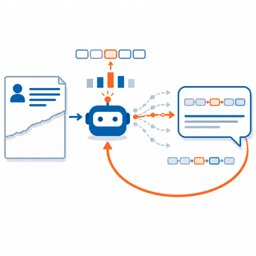

Topic 2: 데이터와 역전파를 통한 사전 학습


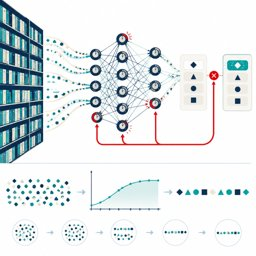

Topic 3: 막대한 연산과 인간 피드백


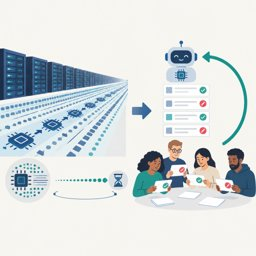

Topic 4: 병렬 처리와 트랜스포머의 수치 표현


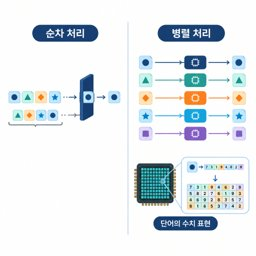

Topic 5: 어텐션과 피드포워드 신경망


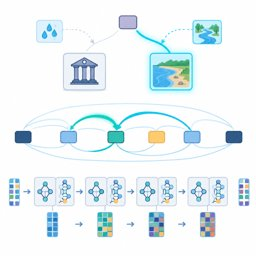

Topic 6: 최종 예측과 모델 해석의 어려움


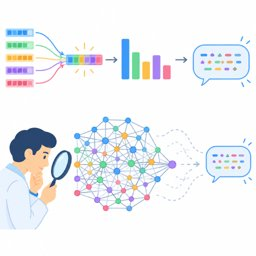

In [12]:
import io
from IPython.display import Image as IPyImage, display
from PIL import Image as PILImage

for i, (topic, img_path) in enumerate(zip(results["topics"], results["image_paths"]), 1):
    print(f"Topic {i}: {topic['title']}")
    img = PILImage.open(img_path)
    img.thumbnail((256, 256))
    buffer = io.BytesIO()
    img.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(IPyImage(data=buffer.getvalue()))